Gestion d'un fonds d'ETF monetaires et de taux

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

In [10]:
tickers =['C3M.PA', 'DBXG.DE', 'INFU.PA', 'EUN6.DE']

data = yf.download(tickers, start = '2019-01-01', end = '2026-09-25', interval = '1wk', auto_adjust = True)

data = data['Close']

print(data)
    



[*********************100%***********************]  4 of 4 completed

Ticker          C3M.PA     DBXG.DE    EUN6.DE     INFU.PA
Date                                                     
2018-12-31  118.175003  343.529999  93.809570   90.080002
2019-01-07  118.160004  344.380005  93.813354   90.139999
2019-01-14  118.150002  345.410004  93.813354   91.220001
2019-01-21  118.135002  352.720001  93.796272   90.470001
2019-01-28  118.120003  352.200012  93.777290   90.550003
...                ...         ...        ...         ...
2026-08-24  127.099998  241.009995  98.720001  121.440002
2026-08-31  127.180000  239.050003  98.748001  122.150002
2026-09-07  127.180000  234.190002  98.720001  122.250000
2026-09-14  127.260002  234.529999  98.739998  122.970001
2026-09-21  127.339996  232.720001  98.790001  124.559998

[404 rows x 4 columns]


In [ ]:
print(data.shape)
print(data.isna().sum())

(404, 4)
Ticker
C3M.PA      0
DBXG.DE     0
EUN6.DE    21
INFU.PA     0
dtype: int64


In [20]:
data = data.dropna()

In [21]:
print(data.isna().sum())

Ticker
C3M.PA     0
DBXG.DE    0
EUN6.DE    0
INFU.PA    0
dtype: int64


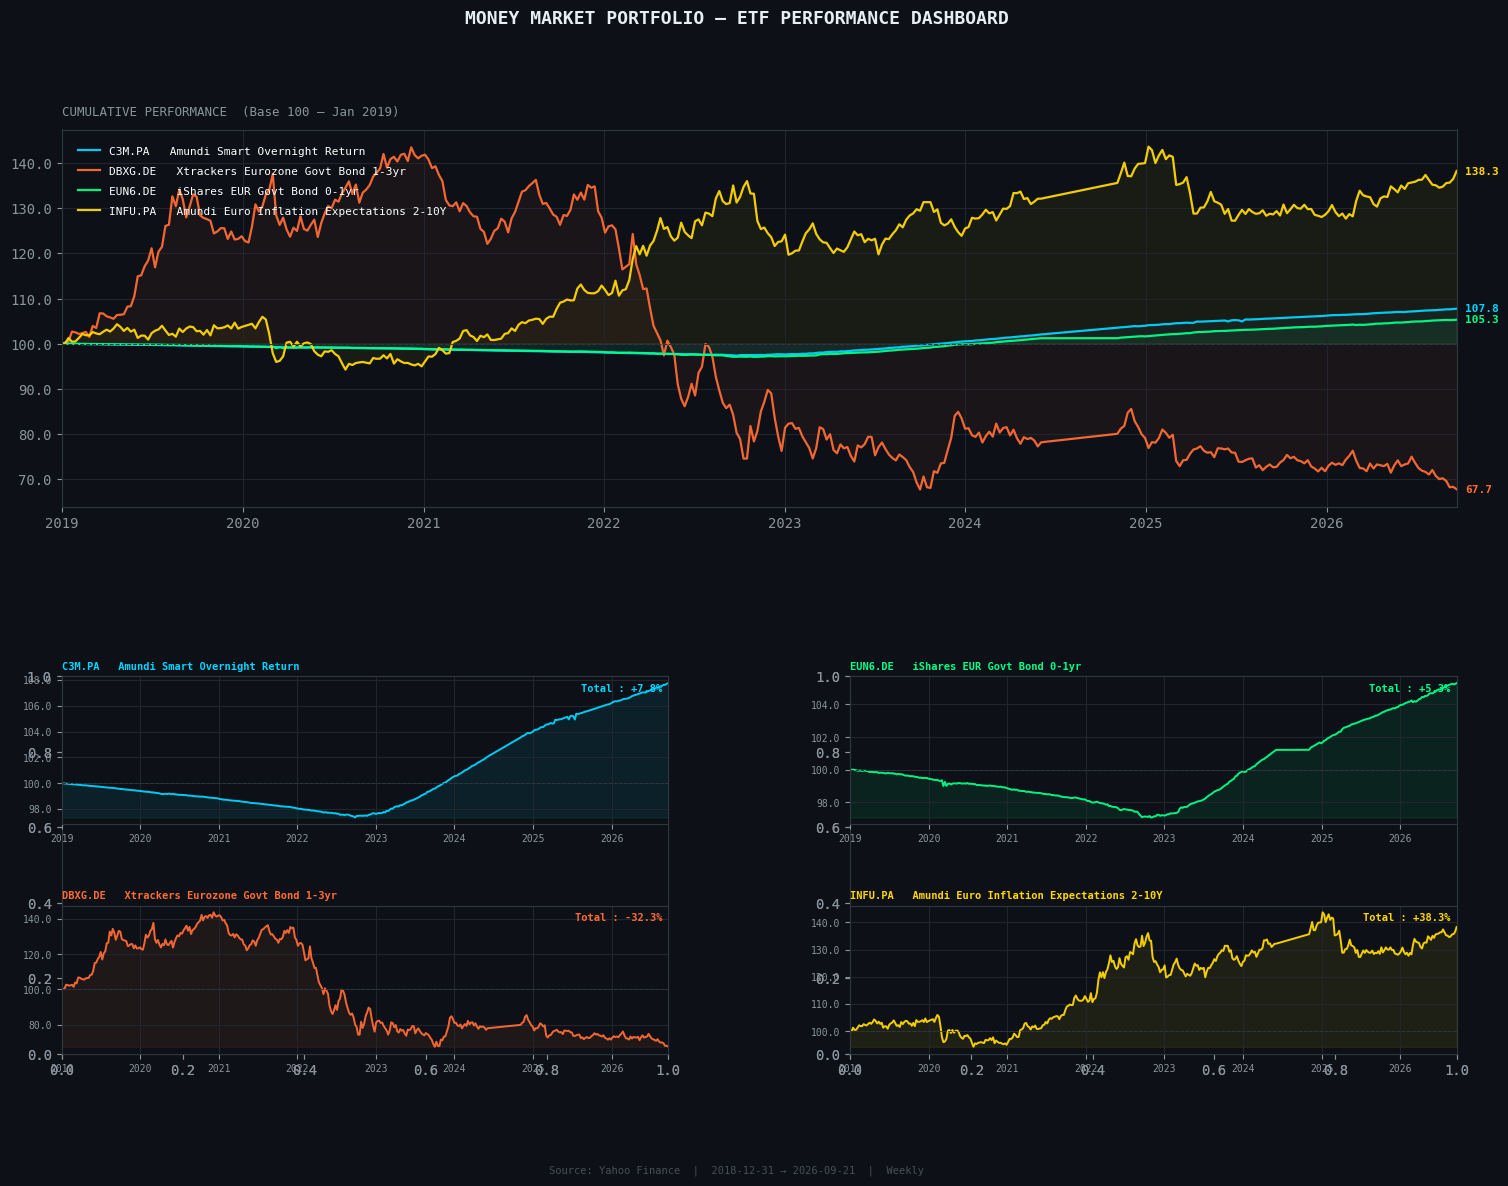

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec
import pandas as pd
import numpy as np

# Base 100
base100 = (data / data.iloc[0]) * 100

# Noms complets
names = {
    'C3M.PA'  : 'Amundi Smart Overnight Return',
    'DBXG.DE' : 'Xtrackers Eurozone Govt Bond 1-3yr',
    'EUN6.DE' : 'iShares EUR Govt Bond 0-1yr',
    'INFU.PA' : 'Amundi Euro Inflation Expectations 2-10Y',
}

# Couleurs
colors = {
    'C3M.PA'  : '#00D4FF',
    'DBXG.DE' : '#FF6B35',
    'EUN6.DE' : '#00FF88',
    'INFU.PA' : '#FFD700',
}

# Style global
plt.rcParams.update({
    'figure.facecolor' : '#0D1117',
    'axes.facecolor'   : '#0D1117',
    'axes.edgecolor'   : '#30363D',
    'axes.labelcolor'  : '#8B949E',
    'xtick.color'      : '#8B949E',
    'ytick.color'      : '#8B949E',
    'grid.color'       : '#21262D',
    'grid.linewidth'   : 0.8,
    'text.color'       : '#E6EDF3',
    'font.family'      : 'monospace',
})

fig = plt.figure(figsize=(18, 12), facecolor='#0D1117')
fig.suptitle('MONEY MARKET PORTFOLIO — ETF PERFORMANCE DASHBOARD',
             fontsize=13, fontweight='bold', color='#E6EDF3',
             y=0.98, fontfamily='monospace')

gs = GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.3)

# ── 1. Performance cumulée tous actifs (grand graphique en haut) 
ax_main = fig.add_subplot(gs[0, :])

for ticker, color in colors.items():
    label = f'{ticker}   {names[ticker]}'
    ax_main.plot(base100.index, base100[ticker],
                 label=label, color=color, linewidth=1.6, alpha=0.95)
    ax_main.fill_between(base100.index, 100, base100[ticker],
                         color=color, alpha=0.05)

ax_main.axhline(100, color='#30363D', linewidth=0.8, linestyle='--')
ax_main.set_title('CUMULATIVE PERFORMANCE  (Base 100 — Jan 2019)',
                  fontsize=9, color='#8B949E', pad=10, loc='left')
ax_main.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f'))
ax_main.legend(loc='upper left', fontsize=8, framealpha=0,
               labelcolor='white', handlelength=2,
               borderpad=1, labelspacing=0.9)
ax_main.grid(True)
ax_main.set_xlim(base100.index[0], base100.index[-1])

# Annotation valeur finale
for ticker, color in colors.items():
    last_val = base100[ticker].iloc[-1]
    ax_main.annotate(f'{last_val:.1f}',
                     xy=(base100.index[-1], last_val),
                     xytext=(6, 0), textcoords='offset points',
                     color=color, fontsize=8, fontweight='bold', va='center')

# ── 2. Évolution individuelle de chaque actif (4 sous-graphiques) ─────────────
axes = [fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 1]),
        fig.add_subplot(gs[1, 1])]

positions = [gs[1, 0], gs[1, 0], gs[1, 1], gs[1, 1]]

# Reconstruction propre des 4 sous-graphiques individuels
axes_ind = []
sub_gs = gs[1, 0].subgridspec(2, 1, hspace=0.55)
axes_ind.append(fig.add_subplot(sub_gs[0]))
axes_ind.append(fig.add_subplot(sub_gs[1]))
sub_gs2 = gs[1, 1].subgridspec(2, 1, hspace=0.55)
axes_ind.append(fig.add_subplot(sub_gs2[0]))
axes_ind.append(fig.add_subplot(sub_gs2[1]))

for ax, (ticker, color) in zip(axes_ind, colors.items()):
    ax.plot(base100.index, base100[ticker],
            color=color, linewidth=1.4, alpha=0.95)
    ax.fill_between(base100.index, base100[ticker].min(), base100[ticker],
                    color=color, alpha=0.08)
    ax.axhline(100, color='#30363D', linewidth=0.7, linestyle='--')

    # Titre avec ticker + nom
    ax.set_title(f'{ticker}   {names[ticker]}',
                 fontsize=7.5, color=color, pad=5, loc='left', fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f'))
    ax.grid(True)
    ax.set_xlim(base100.index[0], base100.index[-1])
    ax.tick_params(labelsize=7)

    # Perf totale en annotation
    perf = base100[ticker].iloc[-1] - 100
    sign = '+' if perf >= 0 else ''
    ax.text(0.99, 0.95, f'Total : {sign}{perf:.1f}%',
            transform=ax.transAxes, fontsize=7.5,
            color=color, ha='right', va='top', fontweight='bold')

# Bandeau bas
fig.text(0.5, 0.01,
         f'Source: Yahoo Finance  |  {data.index[0].date()} → {data.index[-1].date()}  |  Weekly',
         ha='center', fontsize=7.5, color='#484F58', fontfamily='monospace')

plt.savefig('etf_dashboard.png', dpi=180, bbox_inches='tight', facecolor='#0D1117')
plt.show()

In [28]:
import requests
import pandas as pd

def get_estr(start='2019-01-01', end='2026-09-25'):
    """
    Télécharge l'€STR depuis le portail de données de la BCE (SDMX API).
    Série : EST.B.EU000A2X2A25.WT (taux annualisé en %)
    """
    url = (
        "https://data-api.ecb.europa.eu/service/data/EST/"
        "B.EU000A2X2A25.WT"
        "?startPeriod={}&endPeriod={}"
        "&format=csvdata"
    ).format(start, end)

    response = requests.get(url)
    response.raise_for_status()

    from io import StringIO
    df = pd.read_csv(StringIO(response.text))

    # Garder uniquement date et valeur
    estr = df[['TIME_PERIOD', 'OBS_VALUE']].copy()
    estr.columns = ['date', 'estr']
    estr['date']  = pd.to_datetime(estr['date'])
    estr['estr']  = estr['estr'].astype(float)
    estr = estr.set_index('date').sort_index()

    print(f"€STR téléchargé : {len(estr)} observations")
    print(f"Période : {estr.index[0].date()} → {estr.index[-1].date()}")
    print(f"Dernier taux : {estr['estr'].iloc[-1]:.4f}%")

    return estr

estr_daily = get_estr()
print(estr_daily.tail(10))

€STR téléchargé : 1789 observations
Période : 2019-10-01 → 2026-09-24
Dernier taux : 2.4400%
             estr
date             
2026-09-11 2.1890
2026-09-14 2.1900
2026-09-15 2.1900
2026-09-16 2.4410
2026-09-17 2.4400
2026-09-18 2.4410
2026-09-21 2.4400
2026-09-22 2.4400
2026-09-23 2.4390
2026-09-24 2.4400


Convertir l'€STR en rendement cumulé hebdomadaire

L'€STR est un taux annualisé en %. Pour le comparer à vos ETF hebdomadaires, il faut le capitaliser jour par jour puis le rééchantillonner à la semaine :

In [29]:
def estr_to_weekly_returns(estr_daily):
    """
    Convertit le taux €STR annualisé en rendements hebdomadaires capitalisés.
    Convention : Exact/360 (marché monétaire euro)
    """
    estr = estr_daily.copy()

    # Rendement journalier : taux / 360 / 100
    estr['rendement_j'] = estr['estr'] / 360 / 100

    # Indice cumulé (capitalisation quotidienne)
    estr['indice'] = (1 + estr['rendement_j']).cumprod()

    # Rééchantillonnage hebdomadaire (dernier jour ouvré de chaque semaine)
    estr_weekly = estr['indice'].resample('W').last()

    # Rendements hebdomadaires à partir de l'indice
    estr_weekly_ret = estr_weekly.pct_change().dropna()
    estr_weekly_ret.name = 'ESTR'

    return estr_weekly_ret, estr_weekly

estr_ret_weekly, estr_index_weekly = estr_to_weekly_returns(estr_daily)

print("\nRendements hebdomadaires €STR (5 derniers) :")
print((estr_ret_weekly.tail() * 100).round(4))


Rendements hebdomadaires €STR (5 derniers) :
date
2026-08-30   0.0304
2026-09-06   0.0304
2026-09-13   0.0304
2026-09-20   0.0325
2026-09-27   0.0271
Freq: W-SUN, Name: ESTR, dtype: float64


In [32]:
# Rendements hebdomadaires à partir de votre base nettoyée
returns_etf = data.pct_change().dropna()

# Vérification
print(f"Début de votre base ETF : {returns_etf.index[0].date()}")
print(f"Nombre de semaines      : {len(returns_etf)}")
print(returns_etf.head())

Début de votre base ETF : 2019-01-07
Nombre de semaines      : 382
Ticker      C3M.PA  DBXG.DE  EUN6.DE  INFU.PA
Date                                         
2019-01-07 -0.0001   0.0025   0.0000   0.0007
2019-01-14 -0.0001   0.0030   0.0000   0.0120
2019-01-21 -0.0001   0.0212  -0.0002  -0.0082
2019-01-28 -0.0001  -0.0015  -0.0002   0.0009
2019-02-04 -0.0002  -0.0036  -0.0002   0.0076


In [33]:
# Normaliser les index
returns_etf.index         = pd.to_datetime(returns_etf.index).normalize()
estr_ret_weekly.index     = pd.to_datetime(estr_ret_weekly.index).normalize()

# Aligner l'€STR sur les dates des ETF
estr_reindexed = estr_ret_weekly.reindex(returns_etf.index, method='ffill')

# Supprimer les semaines avant octobre 2019
mask = estr_reindexed.notna()
returns_aligned = returns_etf[mask]
estr_aligned    = estr_reindexed[mask]

# Vérification
print(f"Dates retenues     : {returns_aligned.index[0].date()} → {returns_aligned.index[-1].date()}")
print(f"Nombre de semaines : {len(returns_aligned)}")
print(f"NaN dans ETF       : {returns_aligned.isna().sum().sum()}")
print(f"NaN dans €STR      : {estr_aligned.isna().sum()}")

Dates retenues     : 2019-10-14 → 2026-09-21
Nombre de semaines : 342
NaN dans ETF       : 0
NaN dans €STR      : 0


Frais des diferents ETF

In [35]:
# TER annuels
ter_annuel = {
    'C3M.PA'  : 0.0010,   # 10 bps
    'DBXG.DE' : 0.0015,   # 15 bps
    'EUN6.DE' : 0.0010,   # 10 bps
    'INFU.PA' : 0.0025,   # 25 bps
}

# Conversion en coût hebdomadaire
ter_weekly = {t: ter / 52 for t, ter in ter_annuel.items()}

# Rendements nets de frais
returns_net = returns_aligned.copy()
for ticker, cout in ter_weekly.items():
    returns_net[ticker] = returns_aligned[ticker] - cout

print("Impact des frais sur le rendement annuel moyen (bps) :")
impact = (returns_aligned.mean() - returns_net.mean()) * 52 * 10000
print(impact.round(2))

Impact des frais sur le rendement annuel moyen (bps) :
Ticker
C3M.PA    10.0000
DBXG.DE   15.0000
EUN6.DE   10.0000
INFU.PA   25.0000
dtype: float64


In [41]:
# ═══════════════════════════════════════════════════
#  BLOC 1 : PARAMÈTRES
# ═══════════════════════════════════════════════════

FENETRE_ESTIMATION = 52      # semaines pour estimer Sigma et mu
FREQ_REBALANCEMENT = 13      # rebalancement tous les ~3 mois
CIBLE_SURPERF      = 0.005   # +50 bps/an vs €STR
PLANCHER_C3M       = 0.30    # poids minimum sur le monétaire
COUT_TRANSACTION   = 0.0002  # 2 bps par rotation
DATE_SPLIT         = '2023-01-01'

In [43]:
# ═══════════════════════════════════════════════════
#  BLOC 2 : TER ET RENDEMENTS NETS DE FRAIS
# ═══════════════════════════════════════════════════

ter_annuel = {
    'C3M.PA'  : 0.0010,   # 10 bps
    'DBXG.DE' : 0.0015,   # 15 bps
    'EUN6.DE' : 0.0010,   # 10 bps
    'INFU.PA' : 0.0025,   # 25 bps
}
ter_weekly = {t: v / 52 for t, v in ter_annuel.items()}

returns_net = returns_aligned.copy()
for ticker, cout in ter_weekly.items():
    returns_net[ticker] = returns_aligned[ticker] - cout

print("Impact des frais sur le rendement annuel (bps) :")
print(((returns_aligned.mean() - returns_net.mean()) * 52 * 10000).round(2))

Impact des frais sur le rendement annuel (bps) :
Ticker
C3M.PA    10.0000
DBXG.DE   15.0000
EUN6.DE   10.0000
INFU.PA   25.0000
dtype: float64


In [ ]:

#  BLOC 3 : DÉCOUPAGE IN-SAMPLE / OUT-OF-SAMPLE
# ═══════════════════════════════════════════════════

returns_is       = returns_net.loc[:DATE_SPLIT]
returns_oos      = returns_net.loc[DATE_SPLIT:]
returns_brut_is  = returns_aligned.loc[:DATE_SPLIT]
returns_brut_oos = returns_aligned.loc[DATE_SPLIT:]
estr_is          = estr_aligned.loc[:DATE_SPLIT]
estr_oos         = estr_aligned.loc[DATE_SPLIT:]

print("=" * 55)
print("  DÉCOUPAGE IS / OOS")
print("=" * 55)
print(f"  In-Sample  : {returns_is.index[0].date()} → "
      f"{returns_is.index[-1].date()} ({len(returns_is)} semaines)")
print(f"  Out-Sample : {returns_oos.index[0].date()} → "
      f"{returns_oos.index[-1].date()} ({len(returns_oos)} semaines)")
print("=" * 55)

  DÉCOUPAGE IS / OOS
  In-Sample  : 2019-10-14 → 2022-12-26 (168 semaines)
  Out-Sample : 2023-01-02 → 2026-09-21 (174 semaines)


In [45]:
# ═══════════════════════════════════════════════════
#  BLOC 4 : FONCTION D'OPTIMISATION
# ═══════════════════════════════════════════════════

import cvxpy as cp
import numpy as np

def optimiser_te(returns_df, benchmark_series,
                 cible_surperf_annuelle=CIBLE_SURPERF,
                 plancher_c3m=PLANCHER_C3M):
    """
    Minimise la tracking error sous contrainte de surperformance.

    Entrées
    -------
    returns_df            : DataFrame rendements hebdomadaires nets (n x 4)
    benchmark_series      : Series rendements hebdomadaires €STR
    cible_surperf_annuelle: surperformance minimale annuelle (ex: 0.005 = 50 bps)
    plancher_c3m          : poids minimum sur C3M

    Sortie
    ------
    Series des poids optimaux (index = tickers) ou None si infaisable
    """

    tickers   = returns_df.columns.tolist()
    n         = len(tickers)
    active    = returns_df.subtract(benchmark_series, axis=0)
    Sigma     = active.cov().values * 52      # annualisation
    mu_active = active.mean().values * 52

    # Correction numérique si matrice non définie positive
    eigvals = np.linalg.eigvalsh(Sigma)
    if np.any(eigvals < 0):
        Sigma += np.eye(n) * 1e-8

    # Variables et problème
    w       = cp.Variable(n)
    te_sq   = cp.quad_form(w, Sigma)
    idx_c3m = tickers.index('C3M.PA')

    constraints = [
        cp.sum(w) == 1,                                   # budget
        w >= 0,                                            # pas de vente à découvert
        w[idx_c3m] >= plancher_c3m,                       # plancher liquidité
        mu_active @ w >= cible_surperf_annuelle,          # surperformance minimale
    ]

    prob = cp.Problem(cp.Minimize(te_sq), constraints)
    prob.solve(solver=cp.CLARABEL, warm_start=True)

    if prob.status not in ['optimal', 'optimal_inaccurate']:
        return None

    poids = np.maximum(w.value, 0)
    return pd.Series(poids / poids.sum(), index=tickers)

In [ ]:

#  BLOC 5 : FONCTION BACKTEST WALK-FORWARD
 

def backtest_walk_forward(returns_net_df, returns_brut_df,
                          estr_series, label=''):
    """
    Backtest dynamique avec rebalancement trimestriel.

    À chaque rebalancement :
      - Estimation de Sigma et mu sur la fenêtre passée uniquement
      - Optimisation sous contraintes
      - Application des poids sur la période suivante
      - Déduction des coûts de transaction proportionnels à la rotation

    Entrées
    -------
    returns_net_df  : rendements nets de frais
    returns_brut_df : rendements bruts de frais
    estr_series     : rendements hebdomadaires €STR
    label           : 'IN-SAMPLE' ou 'OUT-OF-SAMPLE'

    Sortie
    ------
    dict : poids, perf_brut, perf_net, rebal_dates
    """

    tickers  = returns_net_df.columns.tolist()
    dates    = returns_net_df.index
    n_dates  = len(dates)

    # Initialisation des conteneurs

    historique_poids    = pd.DataFrame(index=dates,
                                       columns=tickers, dtype=float)
    perf_dynamique_brut = pd.Series(index=dates, dtype=float)
    perf_dynamique_net  = pd.Series(index=dates, dtype=float)
    rebalancement_dates = []
    poids_courants      = None
    poids_precedents    = None

    print(f"\n── Backtest {label} ──")

    for i in range(FENETRE_ESTIMATION, n_dates):

        date_courante = dates[i]
        rebalancer    = (i - FENETRE_ESTIMATION) % FREQ_REBALANCEMENT == 0

        # ── Rebalancement 

        if rebalancer or poids_courants is None:

            # Fenêtre glissante : données passées uniquement (no look-ahead)
            ret_f  = returns_net_df.iloc[i - FENETRE_ESTIMATION:i]
            estr_f = estr_series.iloc[i - FENETRE_ESTIMATION:i]

            nouveaux_poids = optimiser_te(ret_f, estr_f)

            if nouveaux_poids is not None:
                poids_precedents = poids_courants
                poids_courants   = nouveaux_poids
                rebalancement_dates.append(date_courante)

                # Coût de transaction
                if poids_precedents is not None:
                    rotation = np.abs(
                        poids_courants.values - poids_precedents.values
                    ).sum()
                    cout_tx = rotation * COUT_TRANSACTION
                else:
                    rotation = 0.0
                    cout_tx  = 0.0

                print(f"  [{date_courante.date()}] "
                      f"C3M:{poids_courants['C3M.PA']*100:.1f}% | "
                      f"DBXG:{poids_courants['DBXG.DE']*100:.1f}% | "
                      f"EUN6:{poids_courants['EUN6.DE']*100:.1f}% | "
                      f"INFU:{poids_courants['INFU.PA']*100:.1f}% | "
                      f"Rotation:{rotation*100:.1f}%")
            else:
                rotation = 0.0
                cout_tx  = 0.0
                print(f"  [{date_courante.date()}] ⚠️  Infaisable — poids inchangés")
        else:
            cout_tx = 0.0

        # ── Enregistrement des performances 

        if poids_courants is not None:
            historique_poids.loc[date_courante] = poids_courants.values

            ret_brut_j = (returns_brut_df.loc[date_courante]
                          * poids_courants).sum()
            ret_net_j  = (returns_net_df.loc[date_courante]
                          * poids_courants).sum()

            perf_dynamique_brut.loc[date_courante] = ret_brut_j - cout_tx
            perf_dynamique_net.loc[date_courante]  = ret_net_j  - cout_tx

    return {
        'poids'       : historique_poids.dropna(),
        'perf_brut'   : perf_dynamique_brut.dropna(),
        'perf_net'    : perf_dynamique_net.dropna(),
        'rebal_dates' : rebalancement_dates,
    }

#  BLOC 6 : LANCEMENT DES BACKTESTS

In [ ]:




res_is  = backtest_walk_forward(
    returns_net_df  = returns_is,
    returns_brut_df = returns_brut_is,
    estr_series     = estr_is,
    label           = 'IN-SAMPLE'
)

res_oos = backtest_walk_forward(
    returns_net_df  = returns_oos,
    returns_brut_df = returns_brut_oos,
    estr_series     = estr_oos,
    label           = 'OUT-OF-SAMPLE'
)


── Backtest IN-SAMPLE ──
  [2020-10-12] C3M:91.2% | DBXG:8.8% | EUN6:0.0% | INFU:0.0% | Rotation:0.0%
  [2021-01-11] C3M:94.8% | DBXG:5.2% | EUN6:0.0% | INFU:0.0% | Rotation:7.2%
  [2021-04-12] C3M:30.0% | DBXG:10.4% | EUN6:50.1% | INFU:9.5% | Rotation:129.6%
  [2021-07-12] C3M:30.0% | DBXG:0.0% | EUN6:55.0% | INFU:15.0% | Rotation:20.8%
  [2021-10-11] C3M:90.6% | DBXG:0.0% | EUN6:2.2% | INFU:7.2% | Rotation:121.2%
  [2022-01-10] C3M:94.1% | DBXG:0.0% | EUN6:0.0% | INFU:5.9% | Rotation:7.0%
  [2022-04-11] C3M:94.8% | DBXG:0.0% | EUN6:0.0% | INFU:5.2% | Rotation:1.3%
  [2022-07-11] C3M:95.5% | DBXG:0.0% | EUN6:0.0% | INFU:4.5% | Rotation:1.6%
  [2022-10-10] C3M:94.9% | DBXG:0.0% | EUN6:0.0% | INFU:5.1% | Rotation:1.3%

── Backtest OUT-OF-SAMPLE ──
  [2024-01-01] C3M:82.6% | DBXG:0.5% | EUN6:16.5% | INFU:0.4% | Rotation:0.0%
  [2024-04-01] C3M:68.0% | DBXG:0.0% | EUN6:31.3% | INFU:0.7% | Rotation:30.3%
  [2024-11-25] C3M:30.0% | DBXG:0.0% | EUN6:70.0% | INFU:0.0% | Rotation:77.3%
  [202

In [49]:
# ═══════════════════════════════════════════════════
#  BLOC 7 : INDICES CUMULÉS
# ═══════════════════════════════════════════════════

def calc_indices(res, estr_series):
    """
    Calcule les indices base 100 et les surperformances cumulées.
    """
    perf_net  = res['perf_net']
    perf_brut = res['perf_brut']
    estr      = estr_series.loc[perf_net.index]

    idx_brut  = (1 + perf_brut).cumprod() * 100
    idx_net   = (1 + perf_net).cumprod()  * 100
    idx_estr  = (1 + estr).cumprod()      * 100
    surp_brut = idx_brut - idx_estr
    surp_net  = idx_net  - idx_estr
    cout      = idx_brut - idx_net

    return idx_brut, idx_net, idx_estr, surp_brut, surp_net, cout


(idx_brut_is,  idx_net_is,  idx_estr_is,
 surp_brut_is,  surp_net_is,  cout_is)  = calc_indices(res_is,  estr_is)

(idx_brut_oos, idx_net_oos, idx_estr_oos,
 surp_brut_oos, surp_net_oos, cout_oos) = calc_indices(res_oos, estr_oos)

  # BLOC 8 : MÉTRIQUES DE PERFORMANCE

In [ ]:




def calc_metriques(res, estr_series):
    """
    Calcule les métriques clés brut et net pour une période.
    """
    pn   = res['perf_net']
    pb   = res['perf_brut']
    estr = estr_series.loc[pn.index]

    ret_b = pb.mean() * 52
    ret_n = pn.mean() * 52
    ret_e = estr.mean() * 52

    sp_b  = (ret_b - ret_e) * 10000    # surperf brute en bps
    sp_n  = (ret_n - ret_e) * 10000    # surperf nette en bps
    vol_b = pb.std() * np.sqrt(52) * 100
    vol_n = pn.std() * np.sqrt(52) * 100
    te_b  = (pb - estr).std() * np.sqrt(52) * 100
    te_n  = (pn - estr).std() * np.sqrt(52) * 100
    ri_b  = sp_b / (te_b * 100) if te_b > 0 else np.nan
    ri_n  = sp_n / (te_n * 100) if te_n > 0 else np.nan

    idx_b = (1 + pb).cumprod()
    idx_n = (1 + pn).cumprod()
    mdd_b = ((idx_b / idx_b.cummax()) - 1).min() * 100
    mdd_n = ((idx_n / idx_n.cummax()) - 1).min() * 100

    return {
        'ret_brut'  : ret_b * 100,
        'ret_net'   : ret_n * 100,
        'sp_brut'   : sp_b,
        'sp_net'    : sp_n,
        'vol_brut'  : vol_b,
        'vol_net'   : vol_n,
        'te_brut'   : te_b,
        'te_net'    : te_n,
        'ri_brut'   : ri_b,
        'ri_net'    : ri_n,
        'mdd_brut'  : mdd_b,
        'mdd_net'   : mdd_n,
        'nb_rebal'  : len(res['rebal_dates']),
    }


m_is  = calc_metriques(res_is,  estr_is)
m_oos = calc_metriques(res_oos, estr_oos)

# Affichage console
print("\n" + "=" * 75)
print(f"  {'Métrique':<28} {'IS Brut':>10} {'IS Net':>10} "
      f"{'OOS Brut':>10} {'OOS Net':>10}")
print("-" * 75)
for nom, k_b, k_n in [
    ('Rendement annualisé (%)', 'ret_brut',  'ret_net'),
    ('Surperf vs €STR (bps)',   'sp_brut',   'sp_net'),
    ('Volatilité (%)',          'vol_brut',  'vol_net'),
    ('Tracking Error (%)',      'te_brut',   'te_net'),
    ("Ratio d'information",     'ri_brut',   'ri_net'),
    ('Max Drawdown (%)',        'mdd_brut',  'mdd_net'),
]:
    print(f"  {nom:<28} {m_is[k_b]:>10.4f} {m_is[k_n]:>10.4f} "
          f"{m_oos[k_b]:>10.4f} {m_oos[k_n]:>10.4f}")
print(f"  {'Nb rebalancements':<28} {m_is['nb_rebal']:>10} {'':>10} "
      f"{m_oos['nb_rebal']:>10}")
print("=" * 75)


  Métrique                        IS Brut     IS Net   OOS Brut    OOS Net
---------------------------------------------------------------------------
  Rendement annualisé (%)          0.1076    -0.0025     2.7369     2.6296
  Surperf vs €STR (bps)           34.5259    23.5152    96.8961    86.1671
  Volatilité (%)                   0.7714     0.7713     0.9295     0.9297
  Tracking Error (%)               0.7767     0.7765     0.9213     0.9215
  Ratio d'information              0.4445     0.3028     1.0517     0.9351
  Max Drawdown (%)                -1.4667    -1.5294    -0.8154    -0.8281
  Nb rebalancements                     9                     8


In [51]:
# ═══════════════════════════════════════════════════
#  BLOC 9 : FONCTIONS GRAPHIQUES UTILITAIRES
# ═══════════════════════════════════════════════════

couleurs = {
    'C3M.PA'  : '#0066CC',
    'DBXG.DE' : '#E63900',
    'EUN6.DE' : '#00994C',
    'INFU.PA' : '#CC8800',
}

plt.rcParams.update({
    'figure.facecolor' : '#FFFFFF',
    'axes.facecolor'   : '#F8F9FA',
    'axes.edgecolor'   : '#CCCCCC',
    'axes.labelcolor'  : '#444444',
    'xtick.color'      : '#666666',
    'ytick.color'      : '#666666',
    'grid.color'       : '#E0E0E0',
    'grid.linewidth'   : 0.8,
    'text.color'       : '#222222',
    'font.family'      : 'monospace',
})

def plot_rebal(ax, dates, index):
    """Trace les lignes verticales de rebalancement."""
    for d in dates:
        if d in index:
            ax.axvline(d, color='#AAAAAA', linewidth=0.5,
                       linestyle=':', alpha=0.6)

def annotate_final(ax, series, couleur, label):
    """Annote la valeur finale d'une courbe."""
    ax.annotate(label,
                xy=(series.index[-1], series.iloc[-1]),
                xytext=(6, 0), textcoords='offset points',
                color=couleur, fontsize=7.5,
                fontweight='bold', va='center')

def plot_performance(ax, idx_brut, idx_net, idx_estr,
                     rebal_dates, titre, couleur_titre):
    """Trace le graphique de performance cumulée base 100."""
    ax.plot(idx_brut.index, idx_brut, color='#0066CC',
            linewidth=1.6, label='Brut')
    ax.plot(idx_net.index,  idx_net,  color='#00994C',
            linewidth=1.6, label='Net')
    ax.plot(idx_estr.index, idx_estr, color='#AAAAAA',
            linewidth=1.2, linestyle='--', label='€STR')
    ax.fill_between(idx_net.index, idx_estr, idx_net,
                    where=idx_net >= idx_estr,
                    color='#00994C', alpha=0.10)
    ax.fill_between(idx_net.index, idx_estr, idx_net,
                    where=idx_net < idx_estr,
                    color='#E63900', alpha=0.10)
    ax.fill_between(idx_brut.index, idx_net, idx_brut,
                    color='#CC8800', alpha=0.12, label='Frais')
    plot_rebal(ax, rebal_dates, idx_net.index)
    annotate_final(ax, idx_brut, '#0066CC', f"Brut:{idx_brut.iloc[-1]:.1f}")
    annotate_final(ax, idx_net,  '#00994C', f"Net:{idx_net.iloc[-1]:.1f}")
    annotate_final(ax, idx_estr, '#888888', f"€STR:{idx_estr.iloc[-1]:.1f}")
    ax.set_title(titre, fontsize=9, loc='left', color=couleur_titre)
    ax.legend(fontsize=7, ncol=4)
    ax.grid(True)

def plot_surperf(ax, surp_brut, surp_net, rebal_dates, titre, couleur_titre):
    """Trace la surperformance cumulée brut vs net."""
    ax.plot(surp_brut.index, surp_brut, color='#0066CC',
            linewidth=1.4, label='Brut')
    ax.plot(surp_net.index,  surp_net,  color='#00994C',
            linewidth=1.4, label='Net')
    ax.fill_between(surp_net.index, surp_brut, surp_net,
                    color='#CC8800', alpha=0.20, label='Frais')
    ax.fill_between(surp_net.index, 0, surp_net,
                    where=surp_net >= 0, color='#00994C', alpha=0.08)
    ax.fill_between(surp_net.index, 0, surp_net,
                    where=surp_net < 0,  color='#E63900', alpha=0.08)
    ax.axhline(0, color='#AAAAAA', linewidth=0.8, linestyle='--')
    plot_rebal(ax, rebal_dates, surp_net.index)
    ax.set_title(titre, fontsize=9, loc='left', color=couleur_titre)
    ax.legend(fontsize=7)
    ax.grid(True)

def plot_poids(ax, historique, rebal_dates, titre, couleur_titre):
    """Trace l'évolution des poids en aires empilées."""
    historique.plot(kind='area', stacked=True, ax=ax,
                    color=[couleurs[c] for c in historique.columns],
                    alpha=0.75)
    plot_rebal(ax, rebal_dates, historique.index)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.set_title(titre, fontsize=9, loc='left', color=couleur_titre)
    ax.legend(fontsize=7, ncol=2)
    ax.grid(True, axis='y')

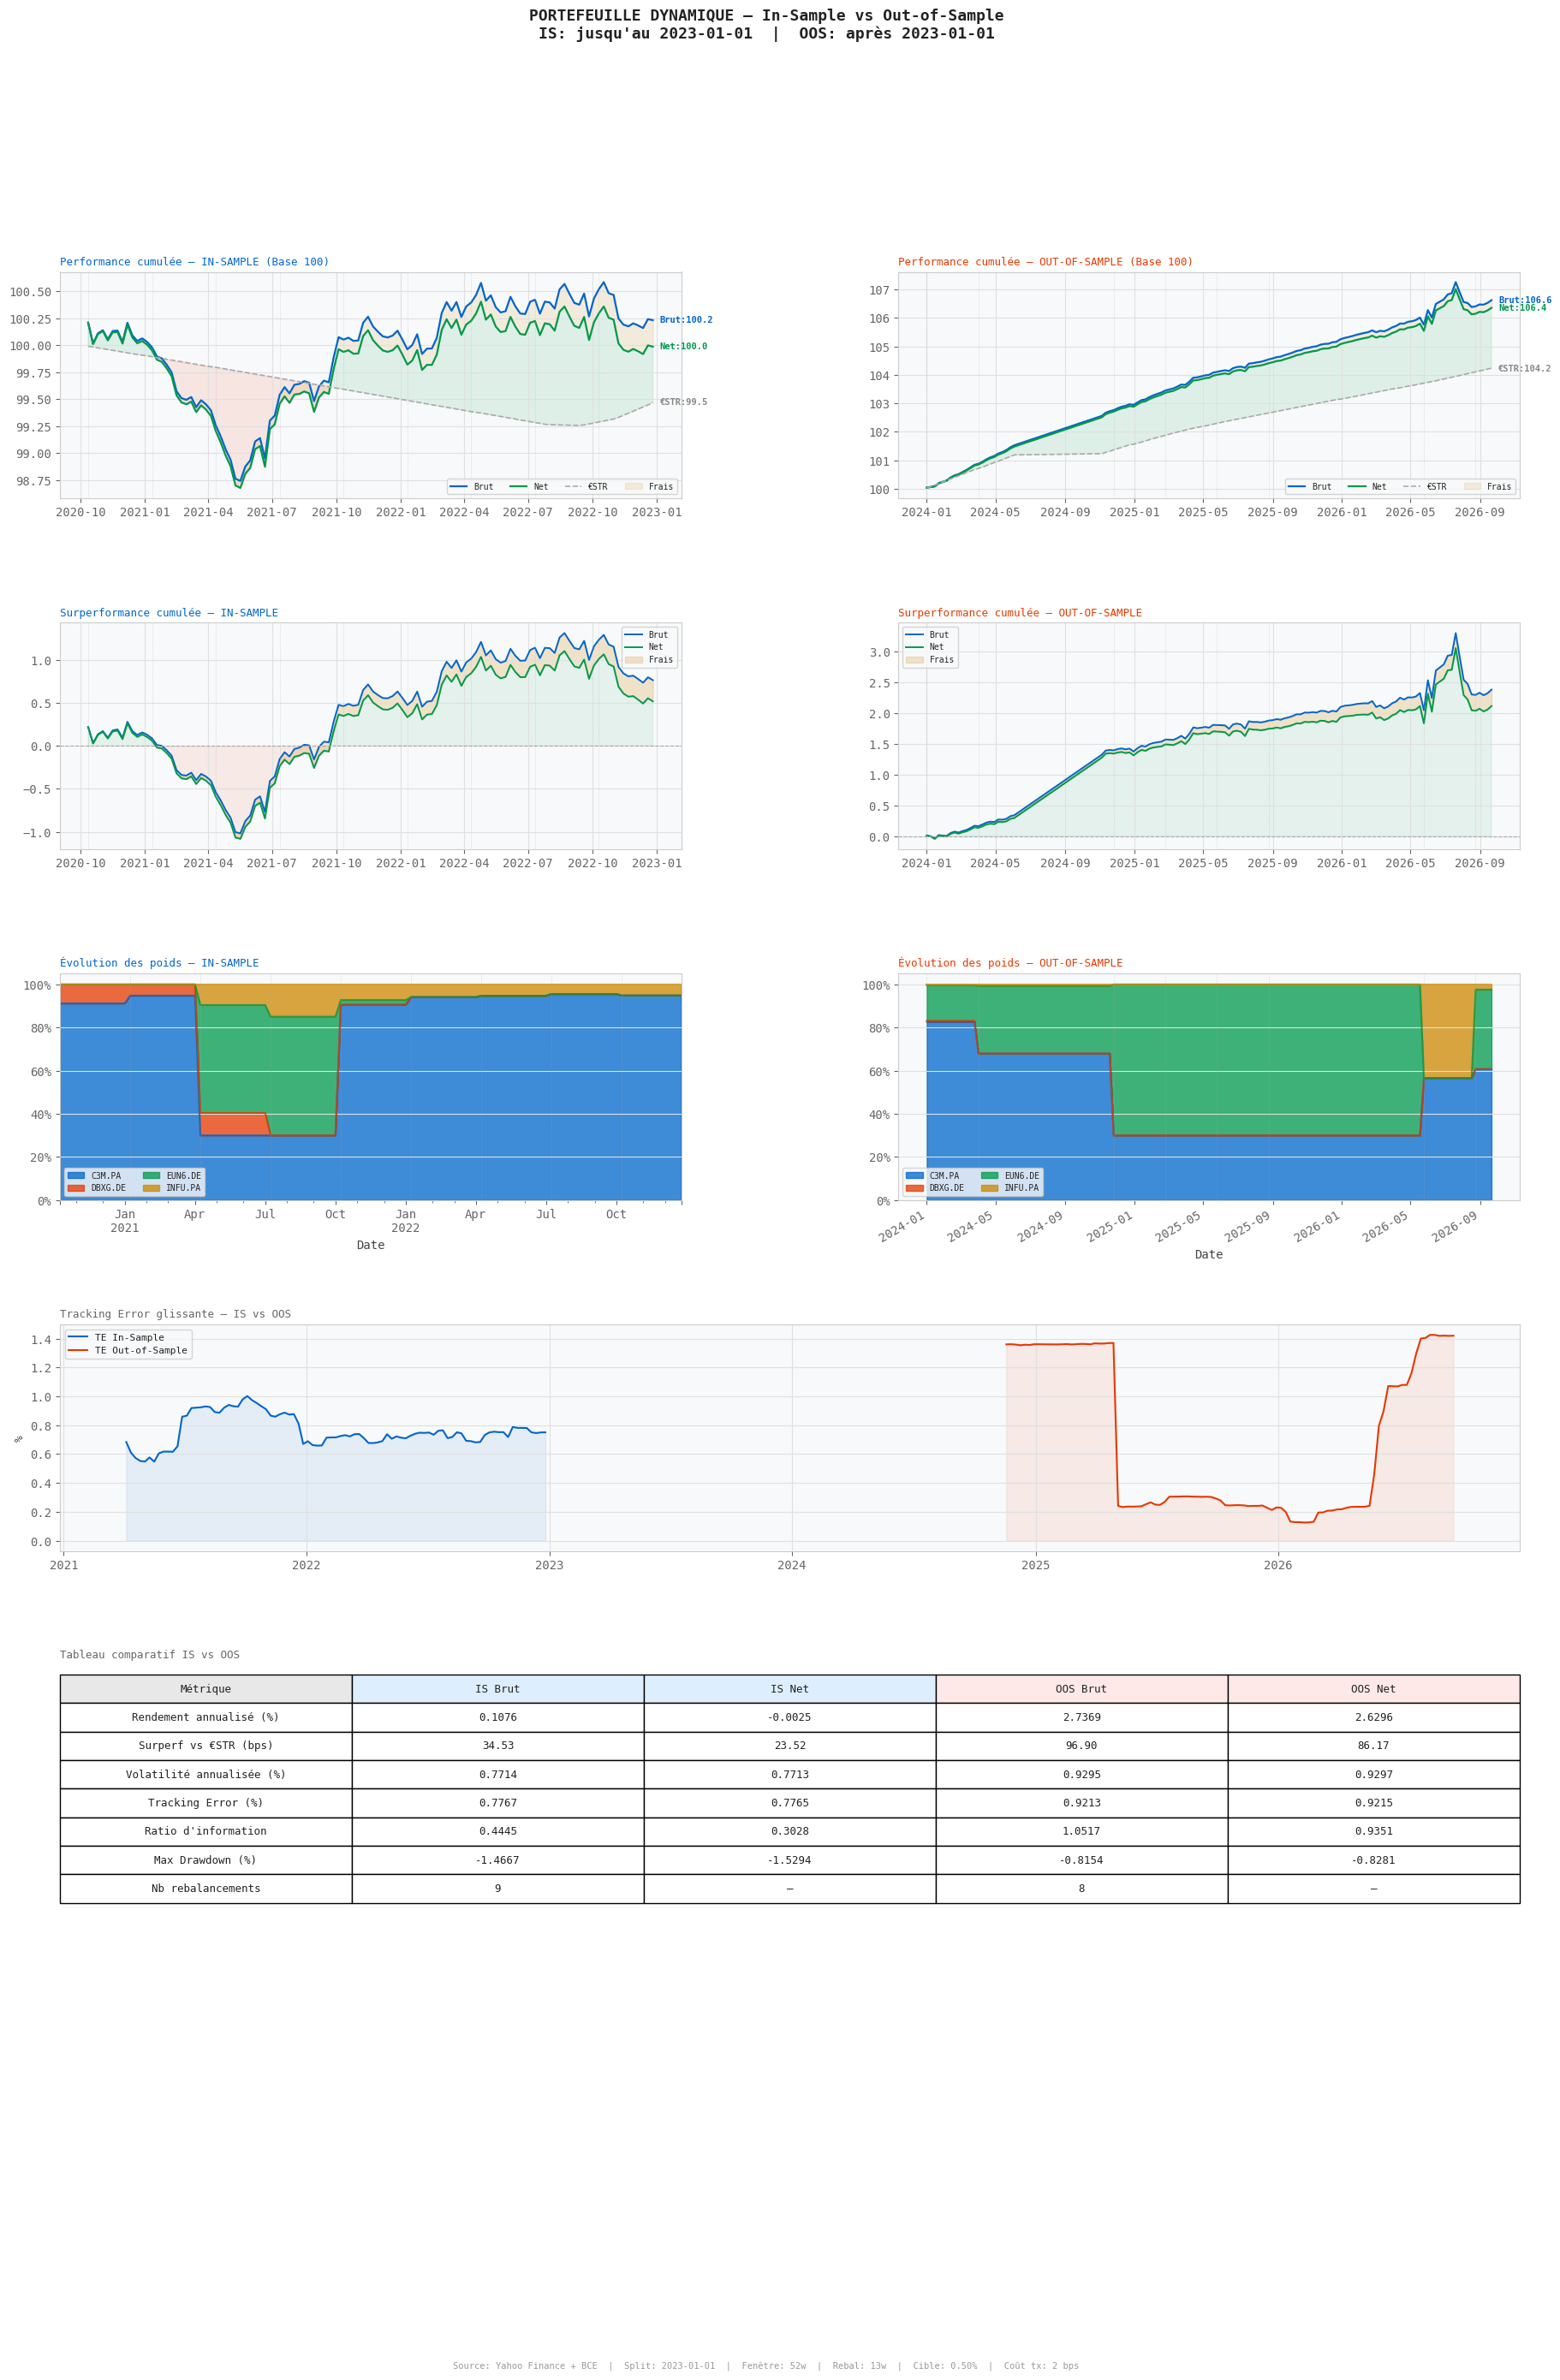

In [ ]:
# ═══════════════════════════════════════════════════
#  BLOC 10 : DASHBOARD FINAL IS vs OOS
# ═══════════════════════════════════════════════════

fig = plt.figure(figsize=(22, 28), facecolor='#FFFFFF')
fig.suptitle(
    'PORTEFEUILLE DYNAMIQUE — In-Sample vs Out-of-Sample\n'
    f'IS: jusqu\'au {DATE_SPLIT}  |  OOS: après {DATE_SPLIT}',
    fontsize=13, fontweight='bold', y=0.99
)
gs = plt.GridSpec(5, 2, figure=fig, hspace=0.55, wspace=0.35)

# ── Ligne 1 : Performance cumulée ─────────────────────────────────────────────
plot_performance(fig.add_subplot(gs[0, 0]),
                 idx_brut_is, idx_net_is, idx_estr_is,
                 res_is['rebal_dates'],
                 'Performance cumulée — IN-SAMPLE (Base 100)', '#0066CC')

plot_performance(fig.add_subplot(gs[0, 1]),
                 idx_brut_oos, idx_net_oos, idx_estr_oos,
                 res_oos['rebal_dates'],
                 'Performance cumulée — OUT-OF-SAMPLE (Base 100)', '#E63900')

# ── Ligne 2 : Surperformance cumulée ──────────────────────────────────────────
plot_surperf(fig.add_subplot(gs[1, 0]),
             surp_brut_is, surp_net_is,
             res_is['rebal_dates'],
             'Surperformance cumulée — IN-SAMPLE', '#0066CC')

plot_surperf(fig.add_subplot(gs[1, 1]),
             surp_brut_oos, surp_net_oos,
             res_oos['rebal_dates'],
             'Surperformance cumulée — OUT-OF-SAMPLE', '#E63900')

# ── Ligne 3 : Évolution des poids ─────────────────────────────────────────────

plot_poids(fig.add_subplot(gs[2, 0]),
           res_is['poids'], res_is['rebal_dates'],
           'Évolution des poids — IN-SAMPLE', '#0066CC')

plot_poids(fig.add_subplot(gs[2, 1]),
           res_oos['poids'], res_oos['rebal_dates'],
           'Évolution des poids — OUT-OF-SAMPLE', '#E63900')

# ── Ligne 4 : Tracking error glissante IS vs OOS ──────────────────────────────

ax_te = fig.add_subplot(gs[3, :])
for res, estr, couleur, label in [
    (res_is,  estr_is,  '#0066CC', 'TE In-Sample'),
    (res_oos, estr_oos, '#E63900', 'TE Out-of-Sample'),
]:
    pn   = res['perf_net']
    e    = estr.loc[pn.index]
    fenetre_te = min(26, len(pn) // 2)
    te_g = (pn - e).rolling(fenetre_te).std() * np.sqrt(52) * 100
    ax_te.plot(te_g.index, te_g, color=couleur, linewidth=1.5, label=label)
    ax_te.fill_between(te_g.index, 0, te_g, color=couleur, alpha=0.08)
ax_te.set_title('Tracking Error glissante — IS vs OOS',
                fontsize=9, loc='left', color='#666666')
ax_te.set_ylabel('%', fontsize=9)
ax_te.legend(fontsize=8)
ax_te.grid(True)

# ── Ligne 5 : Tableau comparatif ──────────────────────────────────────────────

ax_tab = fig.add_subplot(gs[4, :])
ax_tab.axis('off')

lignes_tab = [
    ['Rendement annualisé (%)',
     f"{m_is['ret_brut']:.4f}",  f"{m_is['ret_net']:.4f}",
     f"{m_oos['ret_brut']:.4f}", f"{m_oos['ret_net']:.4f}"],
    ['Surperf vs €STR (bps)',
     f"{m_is['sp_brut']:.2f}",   f"{m_is['sp_net']:.2f}",
     f"{m_oos['sp_brut']:.2f}",  f"{m_oos['sp_net']:.2f}"],
    ['Volatilité annualisée (%)',
     f"{m_is['vol_brut']:.4f}",  f"{m_is['vol_net']:.4f}",
     f"{m_oos['vol_brut']:.4f}", f"{m_oos['vol_net']:.4f}"],
    ['Tracking Error (%)',
     f"{m_is['te_brut']:.4f}",   f"{m_is['te_net']:.4f}",
     f"{m_oos['te_brut']:.4f}",  f"{m_oos['te_net']:.4f}"],
    ["Ratio d'information",
     f"{m_is['ri_brut']:.4f}",   f"{m_is['ri_net']:.4f}",
     f"{m_oos['ri_brut']:.4f}",  f"{m_oos['ri_net']:.4f}"],
    ['Max Drawdown (%)',
     f"{m_is['mdd_brut']:.4f}",  f"{m_is['mdd_net']:.4f}",
     f"{m_oos['mdd_brut']:.4f}", f"{m_oos['mdd_net']:.4f}"],
    ['Nb rebalancements',
     f"{m_is['nb_rebal']}",      '—',
     f"{m_oos['nb_rebal']}",     '—'],
]

table = ax_tab.table(
    cellText   = lignes_tab,
    colLabels  = ['Métrique', 'IS Brut', 'IS Net', 'OOS Brut', 'OOS Net'],
    cellLoc    = 'center',
    loc        = 'center',
    colColours = ['#E8E8E8', '#DDEEFF', '#DDEEFF', '#FFE8E8', '#FFE8E8']
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2.0)
ax_tab.set_title('Tableau comparatif IS vs OOS',
                 fontsize=9, loc='left', color='#666666', pad=15)

# Bandeau bas
fig.text(0.5, 0.005,
         f'Source: Yahoo Finance + BCE  |  Split: {DATE_SPLIT}  |  '
         f'Fenêtre: {FENETRE_ESTIMATION}w  |  Rebal: {FREQ_REBALANCEMENT}w  |  '
         f'Cible: {CIBLE_SURPERF*100:.2f}%  |  Coût tx: {COUT_TRANSACTION*10000:.0f} bps',
         ha='center', fontsize=7.5, color='#999999', fontfamily='monospace')

plt.savefig('is_oos_final.png', dpi=180,
            bbox_inches='tight', facecolor='#FFFFFF')
plt.show()


  CONTRIBUTIONS — IN-SAMPLE
  Ticker          Poids    Rdt net    Surperf     Rq abs    Rq %ptf   Efficience
  ------------------------------------------------------------------------
  C3M.PA         79.41%   -0.5487%   -32.41bps    0.0437%      6.08%      -7.4155
  DBXG.DE         2.73%   -0.4041%   -39.64bps    0.2775%     38.60%      -1.4286
  EUN6.DE        12.03%   -0.1024%    -6.84bps    0.0125%      1.74%      -5.4649
  INFU.PA         5.83%    0.3302%    34.66bps    0.3851%     53.58%       0.9002
  ------------------------------------------------------------------------
  TOTAL         100.00%              -44.22bps    0.7187%    100.00%

  Volatilité active totale : 0.7187%
  Surperformance totale    : -44.22 bps

  CONTRIBUTIONS — OUT-OF-SAMPLE
  Ticker          Poids    Rdt net    Surperf     Rq abs    Rq %ptf   Efficience
  ------------------------------------------------------------------------
  C3M.PA         43.74%    1.2448%    40.72bps    0.2772%     48.97%       1

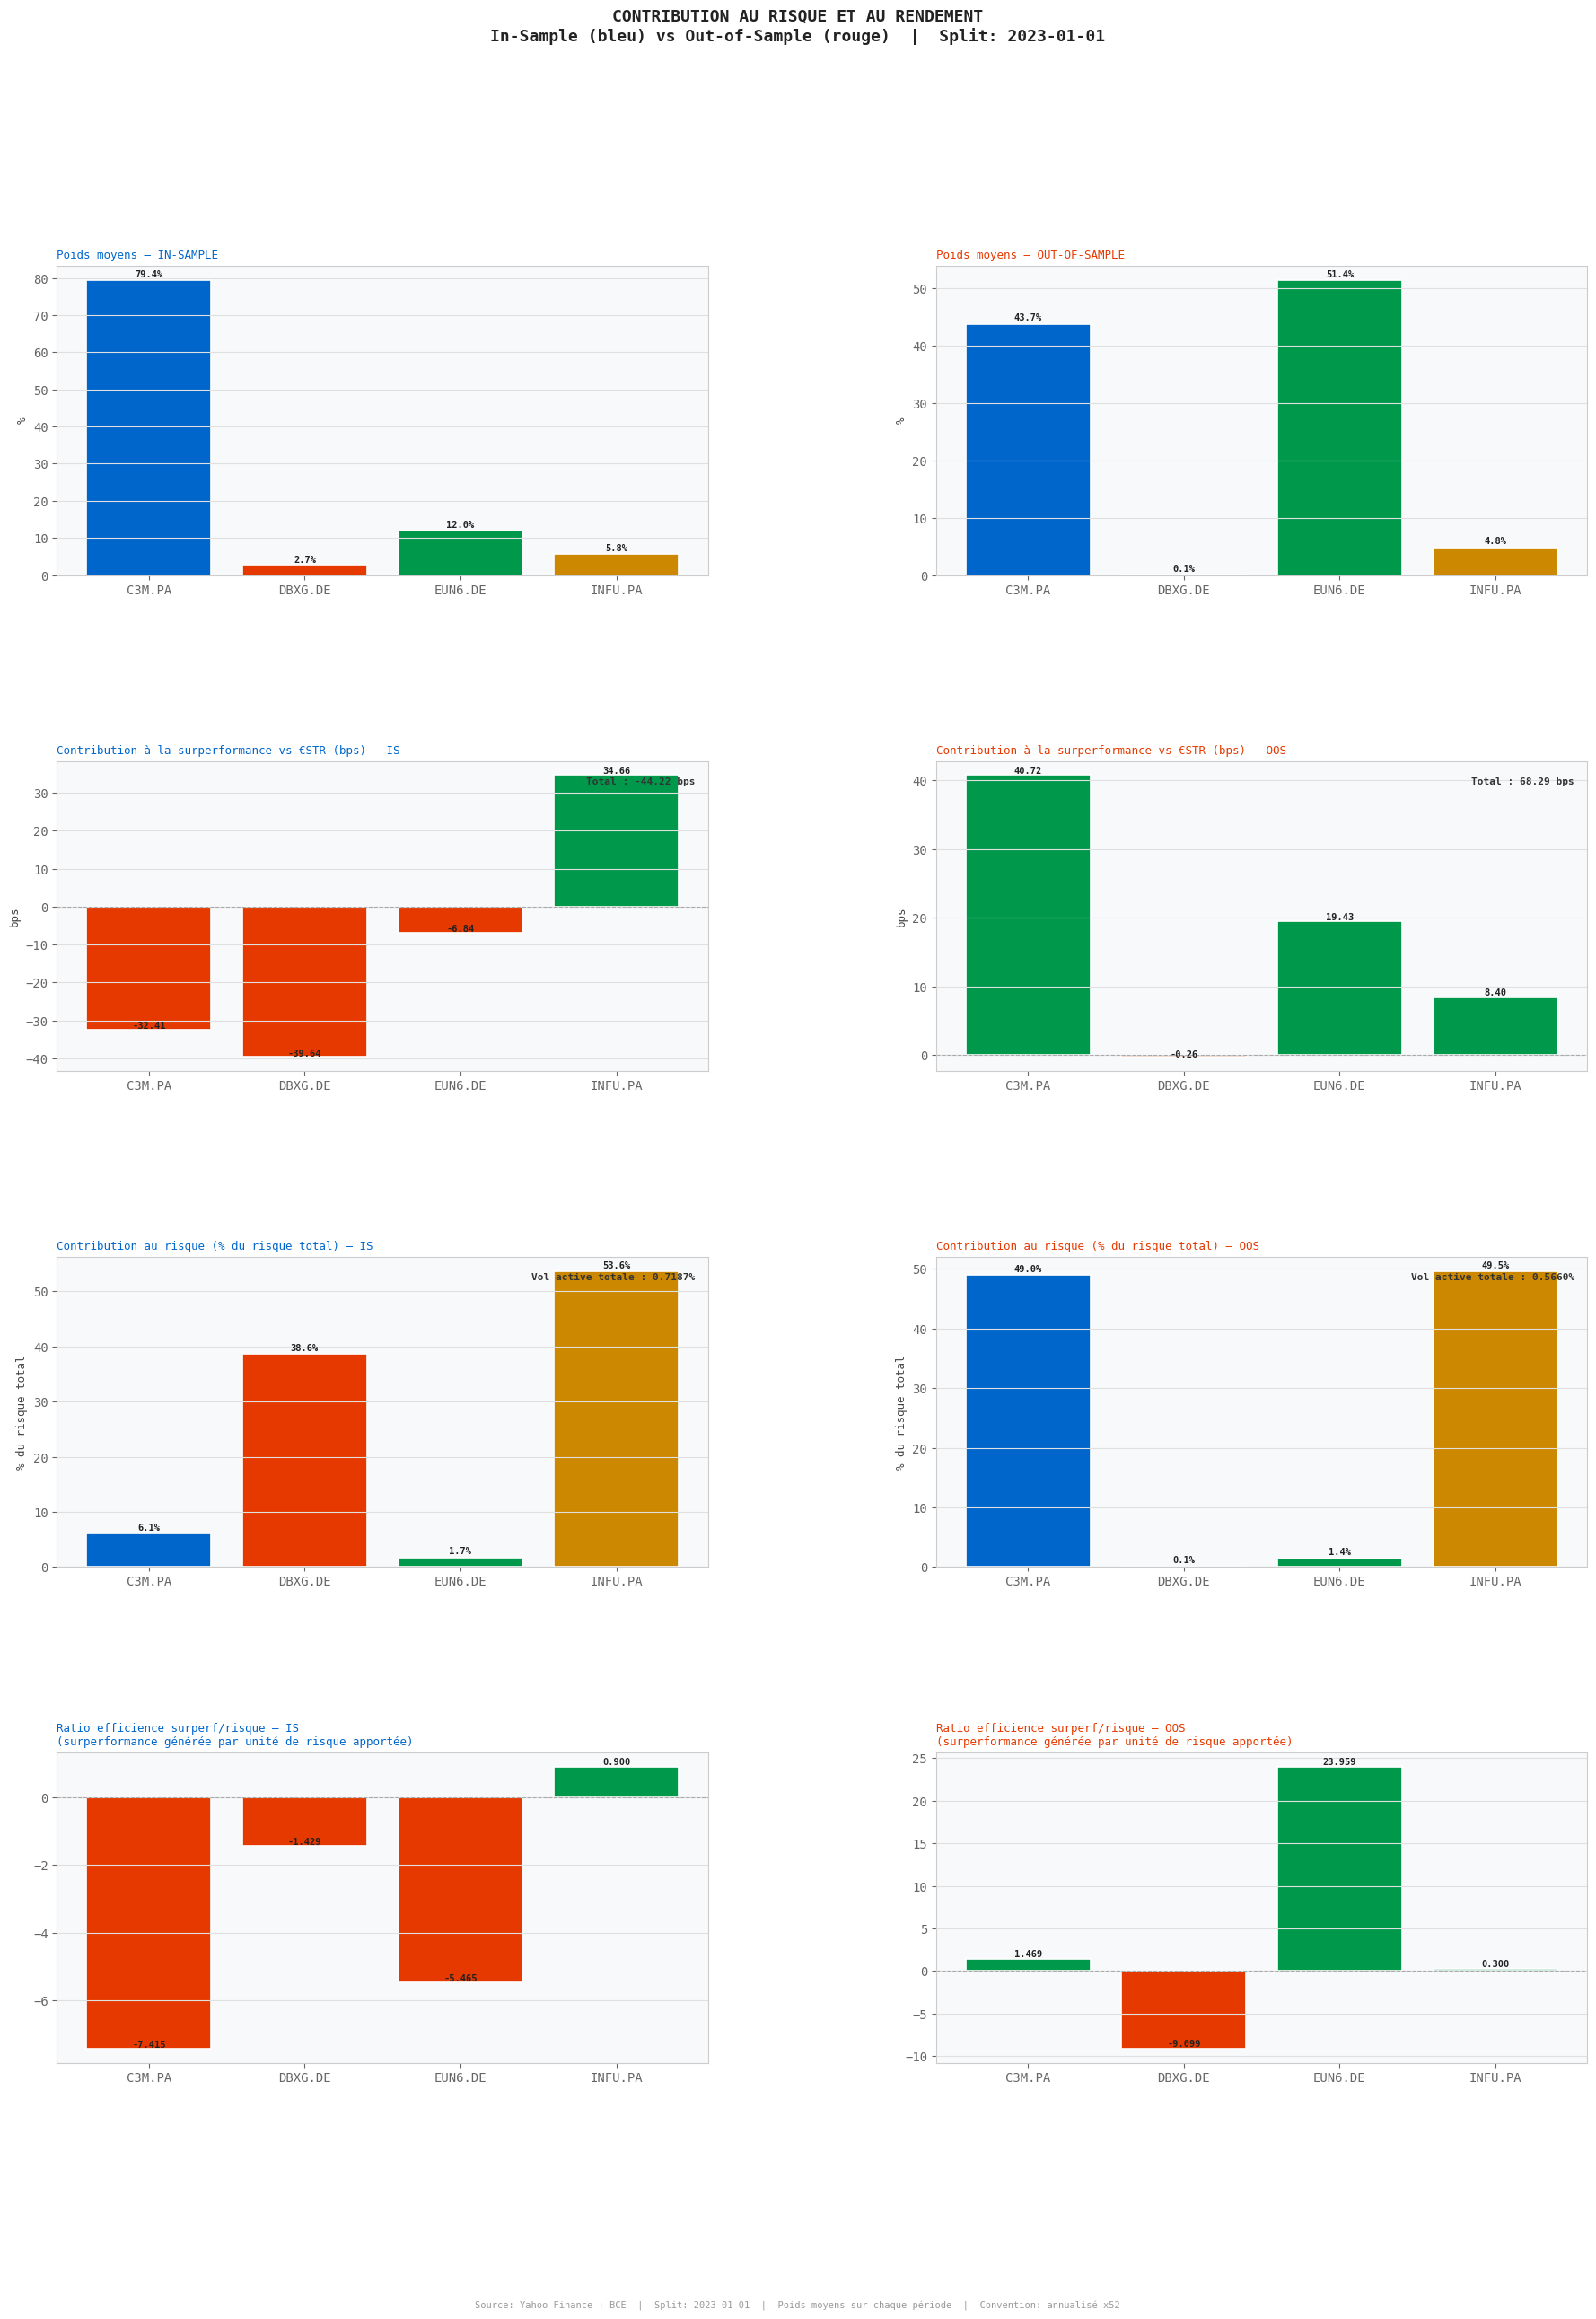

In [ ]:
# ═══════════════════════════════════════════════════
#  BLOC 11 : CONTRIBUTION AU RISQUE ET AU RENDEMENT
#            IS vs OOS
# ═══════════════════════════════════════════════════

def calc_contributions(res, returns_net_df, estr_series):
    """
    Calcule les contributions au risque et au rendement
    pour chaque actif sur une période donnée.

    Entrées
    -------
    res             : dict résultat du backtest (poids, perf_net, ...)
    returns_net_df  : rendements nets sur la période
    estr_series     : rendements €STR sur la période

    Sortie
    ------
    dict contenant toutes les contributions
    """

    tickers = returns_net_df.columns.tolist()

    #  Poids moyens sur la période 
    poids_moyens = res['poids'].mean()

    #  Paramètres statistiques annualisés 
    active    = returns_net_df.subtract(estr_series, axis=0)
    Sigma     = active.cov().values * 52        # matrice de covariance active
    mu_net    = returns_net_df.mean().values * 52
    mu_estr   = estr_series.mean() * 52
    w         = poids_moyens.values

    #  Contribution au rendement 
    contrib_rendement = w * mu_net               # poids x rendement annuel
    contrib_surperf   = w * (mu_net - mu_estr)  # poids x rendement actif

    #  Contribution au risque 

    vol_ptf            = np.sqrt(w @ Sigma @ w)  # volatilité active totale

    contrib_risque_abs = w * (Sigma @ w) / vol_ptf   # contribution absolue

    contrib_risque_pct = contrib_risque_abs / vol_ptf * 100  # en % du total



    # Ratio d'efficience par actif 
    ratio_efficience = contrib_surperf / (contrib_risque_abs + 1e-10)

    return {
        'tickers'           : tickers,
        'poids_moyens'      : poids_moyens,
        'contrib_rendement' : pd.Series(contrib_rendement, index=tickers),
        'contrib_surperf'   : pd.Series(contrib_surperf,   index=tickers),
        'contrib_risque_abs': pd.Series(contrib_risque_abs, index=tickers),
        'contrib_risque_pct': pd.Series(contrib_risque_pct, index=tickers),
        'ratio_efficience'  : pd.Series(ratio_efficience,  index=tickers),
        'vol_ptf'           : vol_ptf * 100,
        'surperf_totale'    : float(w @ (mu_net - mu_estr)) * 10000,
    }


#  Calcul IS et OOS 
contrib_is  = calc_contributions(res_is,  returns_is,  estr_is)
contrib_oos = calc_contributions(res_oos, returns_oos, estr_oos)

#  Affichage console 
for label, c in [('IN-SAMPLE', contrib_is), ('OUT-OF-SAMPLE', contrib_oos)]:
    print(f"\n{'='*70}")
    print(f"  CONTRIBUTIONS — {label}")
    print(f"{'='*70}")
    print(f"  {'Ticker':<12} {'Poids':>8} {'Rdt net':>10} "
          f"{'Surperf':>10} {'Rq abs':>10} {'Rq %ptf':>10} {'Efficience':>12}")
    print(f"  {'-'*72}")
    for t in c['tickers']:
        print(f"  {t:<12} "
              f"{c['poids_moyens'][t]*100:>7.2f}% "
              f"{c['contrib_rendement'][t]*100:>9.4f}% "
              f"{c['contrib_surperf'][t]*10000:>8.2f}bps "
              f"{c['contrib_risque_abs'][t]*100:>9.4f}% "
              f"{c['contrib_risque_pct'][t]:>9.2f}% "
              f"{c['ratio_efficience'][t]:>12.4f}")
    print(f"  {'-'*72}")
    print(f"  {'TOTAL':<12} "
          f"{c['poids_moyens'].sum()*100:>7.2f}% "
          f"{'':>10} "
          f"{c['surperf_totale']:>8.2f}bps "
          f"{c['contrib_risque_abs'].sum()*100:>9.4f}% "
          f"{'100.00%':>10}")
    print(f"\n  Volatilité active totale : {c['vol_ptf']:.4f}%")
    print(f"  Surperformance totale    : {c['surperf_totale']:.2f} bps")

# Style graphique 
couleurs = {
    'C3M.PA'  : '#0066CC',
    'DBXG.DE' : '#E63900',
    'EUN6.DE' : '#00994C',
    'INFU.PA' : '#CC8800',
}
couleurs_list_is  = [couleurs[t] for t in contrib_is['tickers']]
couleurs_list_oos = [couleurs[t] for t in contrib_oos['tickers']]

def bar_labels(ax, bars, fmt='{:.2f}%', offset=0.0002):
    """Ajoute les valeurs au dessus de chaque barre."""
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + (offset if h >= 0 else -offset * 5),
            fmt.format(h),
            ha='center', va='bottom', fontsize=7.5, fontweight='bold'
        )

fig = plt.figure(figsize=(22, 26), facecolor='#FFFFFF')
fig.suptitle(
    'CONTRIBUTION AU RISQUE ET AU RENDEMENT\n'
    f'In-Sample (bleu) vs Out-of-Sample (rouge)  |  Split: {DATE_SPLIT}',
    fontsize=13, fontweight='bold', y=0.99
)
gs = plt.GridSpec(4, 2, figure=fig, hspace=0.60, wspace=0.35)

tickers = contrib_is['tickers']

#  Ligne 1 : Poids moyens IS vs OOS 
ax = fig.add_subplot(gs[0, 0])
bars = ax.bar(tickers,
              contrib_is['poids_moyens'] * 100,
              color=couleurs_list_is, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.1f}%', offset=0.3)
ax.set_title('Poids moyens — IN-SAMPLE',
             fontsize=9, loc='left', color='#0066CC')
ax.set_ylabel('%', fontsize=9)
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')

ax = fig.add_subplot(gs[0, 1])
bars = ax.bar(tickers,
              contrib_oos['poids_moyens'] * 100,
              color=couleurs_list_oos, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.1f}%', offset=0.3)
ax.set_title('Poids moyens — OUT-OF-SAMPLE',
             fontsize=9, loc='left', color='#E63900')
ax.set_ylabel('%', fontsize=9)
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')

#  Ligne 2 : Contribution à la surperformance IS vs OOS 

ax = fig.add_subplot(gs[1, 0])
vals = contrib_is['contrib_surperf'] * 10000
bar_c = ['#00994C' if v >= 0 else '#E63900' for v in vals]
bars = ax.bar(tickers, vals, color=bar_c, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.2f}', offset=0.05)
ax.axhline(0, color='#AAAAAA', linewidth=0.8, linestyle='--')
ax.set_title('Contribution à la surperformance vs €STR (bps) — IS',
             fontsize=9, loc='left', color='#0066CC')
ax.set_ylabel('bps', fontsize=9)
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')
ax.text(0.98, 0.95, f"Total : {contrib_is['surperf_totale']:.2f} bps",
        transform=ax.transAxes, fontsize=8, color='#333333',
        ha='right', va='top', fontweight='bold')

ax = fig.add_subplot(gs[1, 1])
vals = contrib_oos['contrib_surperf'] * 10000
bar_c = ['#00994C' if v >= 0 else '#E63900' for v in vals]
bars = ax.bar(tickers, vals, color=bar_c, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.2f}', offset=0.05)
ax.axhline(0, color='#AAAAAA', linewidth=0.8, linestyle='--')
ax.set_title('Contribution à la surperformance vs €STR (bps) — OOS',
             fontsize=9, loc='left', color='#E63900')
ax.set_ylabel('bps', fontsize=9)
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')
ax.text(0.98, 0.95, f"Total : {contrib_oos['surperf_totale']:.2f} bps",
        transform=ax.transAxes, fontsize=8, color='#333333',
        ha='right', va='top', fontweight='bold')

# ── Ligne 3 : Contribution au risque (% du total) IS vs OOS ──────────────────
ax = fig.add_subplot(gs[2, 0])
bars = ax.bar(tickers,
              contrib_is['contrib_risque_pct'],
              color=couleurs_list_is, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.1f}%', offset=0.3)
ax.set_title('Contribution au risque (% du risque total) — IS',
             fontsize=9, loc='left', color='#0066CC')
ax.set_ylabel('% du risque total', fontsize=9)
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')
ax.text(0.98, 0.95, f"Vol active totale : {contrib_is['vol_ptf']:.4f}%",
        transform=ax.transAxes, fontsize=8, color='#333333',
        ha='right', va='top', fontweight='bold')

ax = fig.add_subplot(gs[2, 1])
bars = ax.bar(tickers,
              contrib_oos['contrib_risque_pct'],
              color=couleurs_list_oos, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.1f}%', offset=0.3)
ax.set_title('Contribution au risque (% du risque total) — OOS',
             fontsize=9, loc='left', color='#E63900')
ax.set_ylabel('% du risque total', fontsize=9)
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')
ax.text(0.98, 0.95, f"Vol active totale : {contrib_oos['vol_ptf']:.4f}%",
        transform=ax.transAxes, fontsize=8, color='#333333',
        ha='right', va='top', fontweight='bold')

# ── Ligne 4 : Ratio efficience (surperf / risque) IS vs OOS ──────────────────
ax = fig.add_subplot(gs[3, 0])
vals = contrib_is['ratio_efficience']
bar_c = ['#00994C' if v >= 0 else '#E63900' for v in vals]
bars = ax.bar(tickers, vals, color=bar_c, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.3f}', offset=0.002)
ax.axhline(0, color='#AAAAAA', linewidth=0.8, linestyle='--')
ax.set_title('Ratio efficience surperf/risque — IS\n'
             '(surperformance générée par unité de risque apportée)',
             fontsize=9, loc='left', color='#0066CC')
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')

ax = fig.add_subplot(gs[3, 1])
vals = contrib_oos['ratio_efficience']
bar_c = ['#00994C' if v >= 0 else '#E63900' for v in vals]
bars = ax.bar(tickers, vals, color=bar_c, edgecolor='white', linewidth=1.2)
bar_labels(ax, bars, fmt='{:.3f}', offset=0.002)
ax.axhline(0, color='#AAAAAA', linewidth=0.8, linestyle='--')
ax.set_title('Ratio efficience surperf/risque — OOS\n'
             '(surperformance générée par unité de risque apportée)',
             fontsize=9, loc='left', color='#E63900')
ax.grid(True, axis='y')
ax.set_facecolor('#F8F9FA')

# Bandeau bas
fig.text(0.5, 0.005,
         f'Source: Yahoo Finance + BCE  |  Split: {DATE_SPLIT}  |  '
         f'Poids moyens sur chaque période  |  Convention: annualisé x52',
         ha='center', fontsize=7.5, color='#999999', fontfamily='monospace')

plt.savefig('contributions_is_oos.png', dpi=180,
            bbox_inches='tight', facecolor='#FFFFFF')
plt.show()